# Iris Flower Classification
**Oasis Infobyte Internship · Python Track · Task 1**

**Objective:** Train machine learning classifiers to predict the species of an iris flower (*Setosa*, *Versicolor* or *Virginica*) from its sepal and petal measurements.

**Workflow:** Load data → EDA → Visualisation → Feature discussion → Train/test split → Train models → Evaluate → Pick the best model

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the Dataset
The Iris dataset ships with scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Replace numeric targets (0, 1, 2) with readable species names
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")
df.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in df.columns]

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

### 3.1 Shape, data types and null values

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nNull values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (150, 5)

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

Null values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1


### 3.2 Descriptive statistics

In [4]:
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### 3.3 Class balance

In [5]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Observations:**
- The dataset has 150 rows and 4 numeric features plus the species label.
- There are no missing values, so no imputation is required.
- The classes are perfectly balanced (50 samples each), so accuracy is a fair metric here.
- A few rows are exact duplicates (a known quirk of this dataset). With only 150 rows I keep them, as they have no meaningful effect on the results.

## 4. Visualisations

### 4.1 Pairplot: feature distributions by species

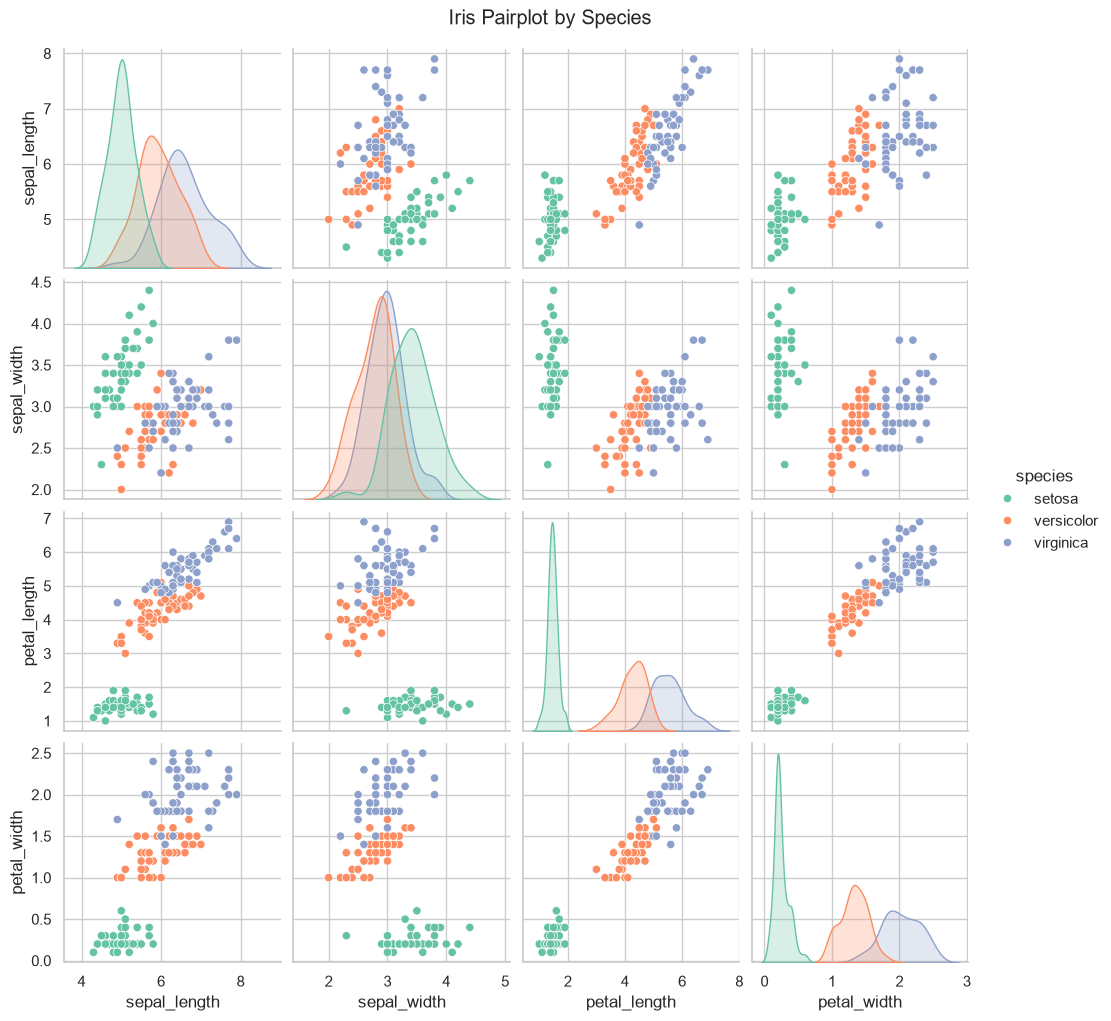

In [6]:
sns.pairplot(df, hue="species", diag_kind="kde", palette="Set2")
plt.suptitle("Iris Pairplot by Species", y=1.02)
plt.show()

**Observations:** Setosa is clearly separated from the other two species, especially in the petal measurements. Versicolor and Virginica overlap slightly, which is where a classifier is most likely to make mistakes.

### 4.2 Box plots for each feature

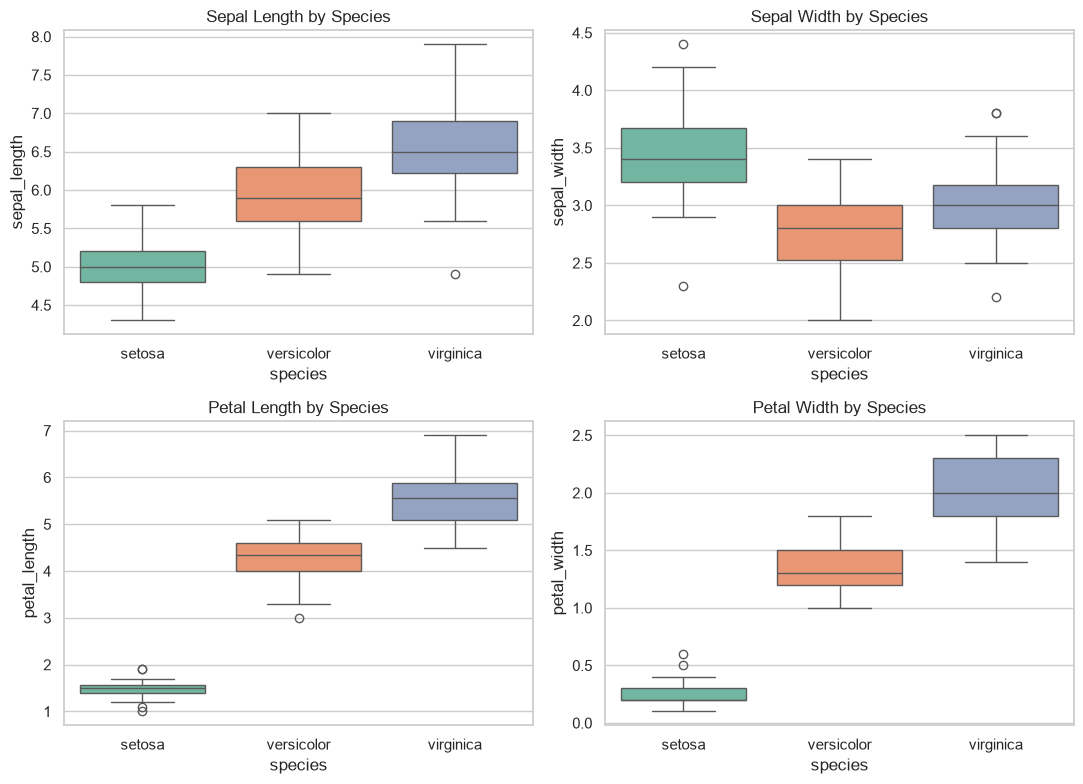

In [7]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feature, hue="species", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by Species")
plt.tight_layout()
plt.show()

**Observations:** Petal length and petal width show almost no overlap between Setosa and the others, and only a small overlap between Versicolor and Virginica. Sepal width has the most overlap across all three species.

### 4.3 Correlation heatmap

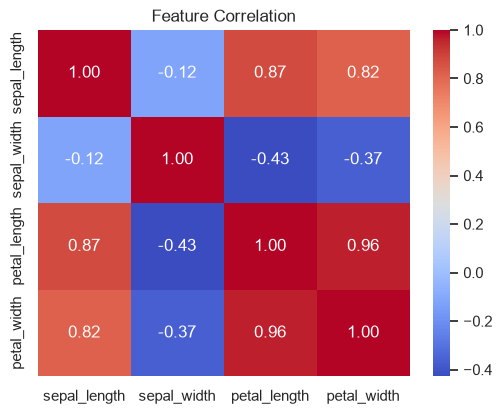

In [8]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation")
plt.show()

## 5. Feature Selection Discussion: Which Features Are Most Discriminative?

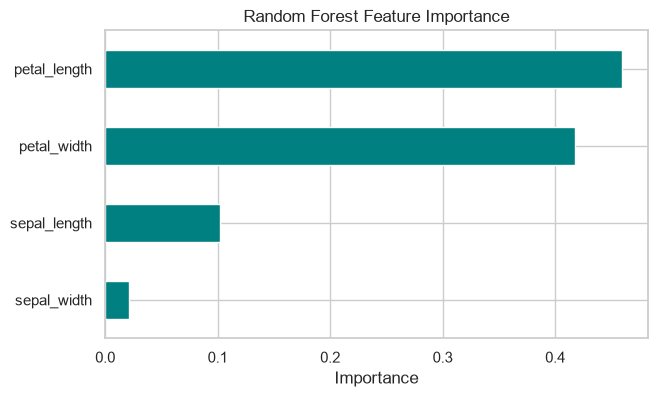

petal_length    0.459
petal_width     0.418
sepal_length    0.102
sepal_width     0.021
dtype: float64


In [9]:
# Quantify discriminative power with a Random Forest's feature importances
X_all = df[features]
y_all = df["species"]

rf_check = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_all, y_all)
importances = pd.Series(rf_check.feature_importances_, index=features).sort_values()

importances.plot(kind="barh", color="teal", figsize=(7, 4), title="Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

print(importances.sort_values(ascending=False).round(3))

**Discussion:**
- **Petal length and petal width** are the most discriminative features. They separate Setosa completely and divide Versicolor from Virginica well.
- **Sepal length** contributes moderately.
- **Sepal width** is the weakest feature, since its distributions overlap heavily across species.
- Petal length and petal width are also strongly correlated with each other, so they carry overlapping information. Using all four features still gives the best results, as the dataset is small and low-dimensional.

## 6. Train/Test Split
An 80/20 split, stratified so each species is equally represented in both sets.m

In [10]:
X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])

Training samples: 120
Testing samples:  30


## 7. Train the Classifiers
I train four models. Logistic Regression and KNN are distance/scale-sensitive, so they are wrapped in a pipeline with `StandardScaler`. Tree-based models do not need scaling.

In [11]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: K-Nearest Neighbours
Trained: Decision Tree
Trained: Random Forest


## 8. Evaluate Each Model
For each model: accuracy, confusion matrix and a classification report (precision, recall, F1).

Logistic Regression  |  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



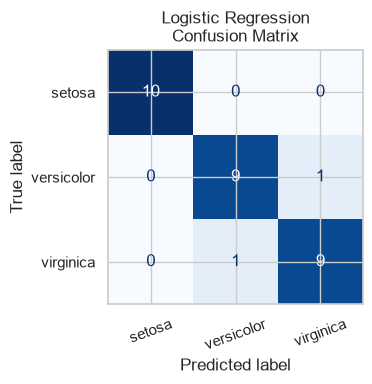

K-Nearest Neighbours  |  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



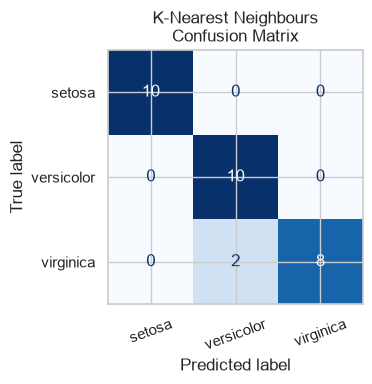

Decision Tree  |  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



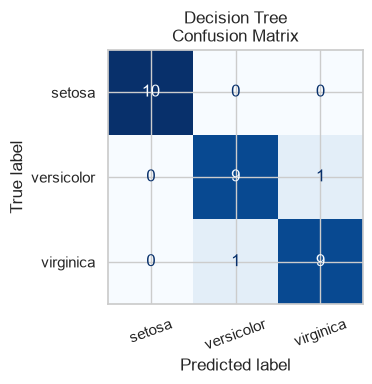

Random Forest  |  Test accuracy: 0.9000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



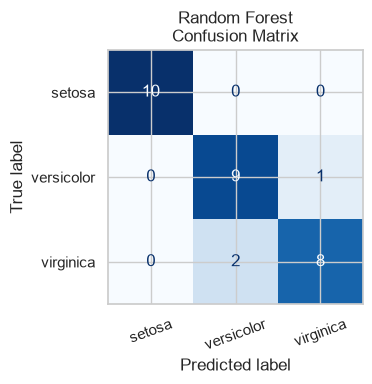

In [12]:
results = {}
labels = iris.target_names

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print("=" * 60)
    print(f"{name}  |  Test accuracy: {acc:.4f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=labels))

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"{name}\nConfusion Matrix")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### Reading the results
- **Accuracy:** share of all predictions that were correct.
- **Precision:** of the flowers predicted as a species, how many truly were that species.
- **Recall:** of the flowers that truly belong to a species, how many the model found.
- **F1-score:** the harmonic mean of precision and recall.
- **Confusion matrix:** rows are true species, columns are predictions. Anything off the diagonal is a mistake.

## 9. Compare Models and Declare the Best

A single 30-sample test set is small, so one lucky or unlucky split can distort the ranking. To make the comparison more reliable, I also use **5-fold stratified cross-validation** on the full dataset.

In [13]:
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    cv_rows.append({
        "Model": name,
        "Test Accuracy": results[name],
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std(),
    })

comparison = pd.DataFrame(cv_rows).sort_values("CV Mean Accuracy", ascending=False).reset_index(drop=True)
comparison.round(4)

,Model,Test Accuracy,CV Mean Accuracy,CV Std
0,Random Forest,0.9000,0.9667,0.0211
1,Logistic Regression,0.9333,0.9600,0.0389
2,K-Nearest Neighbours,0.9333,0.9600,0.0249
3,Decision Tree,0.9333,0.9533,0.0340


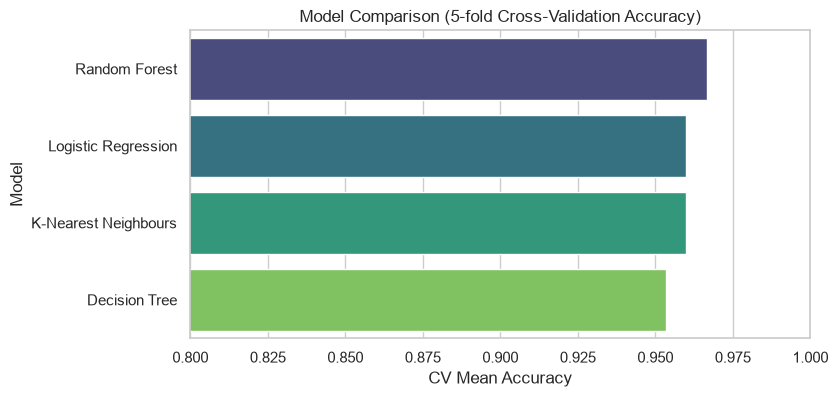

Best-performing model (by cross-validated accuracy): Random Forest


In [14]:
plt.figure(figsize=(8, 4))
sns.barplot(data=comparison, x="CV Mean Accuracy", y="Model", hue="Model", palette="viridis", legend=False)
plt.xlim(0.8, 1.0)
plt.title("Model Comparison (5-fold Cross-Validation Accuracy)")
plt.show()

best_model_name = comparison.loc[0, "Model"]
print(f"Best-performing model (by cross-validated accuracy): {best_model_name}")

### Conclusion
**Best model: Random Forest** (5-fold CV accuracy 0.9667, std 0.0211).

**Justification:**
1. It has the highest cross-validated accuracy and the lowest variance across folds, so it is the most stable.
2. Its lower score on the single 30-sample test split (0.90, two more mistakes than the others) reflects the small test set rather than weaker performance. Cross-validation uses all 150 samples and is more reliable.
3. Its errors are confined to Versicolor vs. Virginica, while Setosa is classified perfectly.

**Key takeaways:**
- Petal length and petal width are the most informative features.
- All four models score between 0.95 and 0.97 in cross-validation, so the differences are small. Logistic Regression is a strong, simpler alternative.

## 10. Predict on a New Flower (Bonus)

In [15]:
best_model = models[best_model_name]

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]], columns=features
)  # sepal length, sepal width, petal length, petal width (cm)

print("Predicted species:", best_model.predict(new_flower)[0])

Predicted species: setosa
